# 03 - Optimisation des hyperparamètres avec Optuna

Recherche des hyperparamètres du meilleur modèle linéaire (Ridge) et du meilleur modèle non linéaire (HistGradientBoosting) identifiés dans le notebook 02, suivi de chaque essai dans MLflow, sélection du modèle final et export.

Protocole :
- le découpage train / test est identique à celui du notebook 02 (80 / 20, seed 42) ;
- la recherche utilise une validation croisée sur un échantillon du jeu d'entraînement, le jeu de test n'intervient pas ;
- le modèle final est choisi sur le RMSE de validation croisée ;
- les modèles retenus sont réentraînés sur l'ensemble du jeu d'entraînement puis évalués une fois sur le jeu de test.

## 1. Imports et configuration

In [1]:
import gc
import json
import platform
import socket
import subprocess
import sys
import time
import urllib.request
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
import sklearn
from mlflow import MlflowClient
from mlflow.models import infer_signature
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")

SEED = 42
np.random.seed(SEED)

DATA_RAW = Path("../data/raw")
DATA_PROCESSED = Path("../data/processed")
FIG_DIR = Path("../reports/figures")
MODELS_DIR = Path("../models")
for d in (DATA_PROCESSED, FIG_DIR, MODELS_DIR):
    d.mkdir(parents=True, exist_ok=True)

TARGET = "Yield_tons_per_hectare"

# Paramètres de la recherche
N_TUNE_SAMPLE = 100_000
CV_FOLDS = 5
MODEL_NAMES = ["ridge", "hist-gradient-boosting"]
N_TRIALS = {"ridge": 40, "hist-gradient-boosting": 40}
SIMPLE_MODEL = "ridge"
TOLERANCE_SELECTION = 0.001

EXPERIMENT_NAME = "crop-yield-optimisation"
REGISTRY_NAME = "crop-yield-regressor"

print(f"python {platform.python_version()} | mlflow {mlflow.__version__} | optuna {optuna.__version__} | scikit-learn {sklearn.__version__} | pandas {pd.__version__}")

python 3.11.9 | mlflow 3.17.2 | optuna 5.0.0 | scikit-learn 1.9.1 | pandas 3.1.0


## 2. MLflow

Configuration du suivi sur la même base que le notebook 02 (`mlflow.db`), création de l'expérience `crop-yield-optimisation` et lancement du serveur de l'interface sur le port 5000 s'il n'est pas déjà actif.

In [2]:
PROJECT_ROOT = Path("..").resolve()
DB_PATH = PROJECT_ROOT / "mlflow.db"
ARTIFACT_ROOT = PROJECT_ROOT / "mlruns"
TRACKING_URI = f"sqlite:///{DB_PATH.as_posix()}"
MLFLOW_PORT = 5000
MLFLOW_URL = f"http://127.0.0.1:{MLFLOW_PORT}"

mlflow.set_tracking_uri(TRACKING_URI)
if mlflow.get_experiment_by_name(EXPERIMENT_NAME) is None:
    mlflow.create_experiment(EXPERIMENT_NAME, artifact_location=ARTIFACT_ROOT.as_uri())
mlflow.set_experiment(EXPERIMENT_NAME)


def port_open(port, host="127.0.0.1"):
    with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as s:
        s.settimeout(0.5)
        return s.connect_ex((host, port)) == 0


if port_open(MLFLOW_PORT):
    print(f"Serveur MLflow déjà actif sur {MLFLOW_URL}")
else:
    log_file = open(PROJECT_ROOT / "mlflow_ui.log", "w")
    mlflow_proc = subprocess.Popen(
        [sys.executable, "-m", "mlflow", "ui",
         "--backend-store-uri", TRACKING_URI,
         "--port", str(MLFLOW_PORT), "--host", "127.0.0.1"],
        stdout=log_file, stderr=subprocess.STDOUT,
    )
    for _ in range(40):
        if port_open(MLFLOW_PORT):
            break
        time.sleep(0.5)
    print("Serveur MLflow lancé" if port_open(MLFLOW_PORT) else "Échec du lancement (voir mlflow_ui.log)")

try:
    status = urllib.request.urlopen(MLFLOW_URL, timeout=5).status
    print(f"Interface MLflow accessible : {MLFLOW_URL} (HTTP {status})")
except Exception as e:
    print("Interface MLflow non joignable :", e)
print("Expérience active :", EXPERIMENT_NAME)

Serveur MLflow déjà actif sur http://127.0.0.1:5000
Interface MLflow accessible : http://127.0.0.1:5000 (HTTP 200)
Expérience active : crop-yield-optimisation


## 3. Données et découpage

Chargement du jeu nettoyé et reproduction du découpage du notebook 02. Un échantillon de `N_TUNE_SAMPLE` lignes du jeu d'entraînement sert à la recherche ; le jeu d'entraînement complet sert au réentraînement final.

In [3]:
clean_path = DATA_PROCESSED / "crop_yield_clean.csv"
if clean_path.exists():
    df = pd.read_csv(clean_path)
else:
    df = pd.read_csv(DATA_RAW / "crop_yield.csv").drop_duplicates()
    df = df[df[TARGET] >= 0].reset_index(drop=True)
    df.to_csv(clean_path, index=False)
    print("CSV nettoyé reconstruit et enregistré.")

num_cols = ["Rainfall_mm", "Temperature_Celsius", "Days_to_Harvest"]
bool_cols = ["Fertilizer_Used", "Irrigation_Used"]
cat_cols = ["Region", "Soil_Type", "Crop", "Weather_Condition"]
FEATURES = num_cols + bool_cols + cat_cols

X = df[FEATURES].copy()
X[bool_cols] = X[bool_cols].astype(int)
y = df[TARGET]
crops = sorted(df["Crop"].unique())

X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
X_tune = X_train_full.sample(N_TUNE_SAMPLE, random_state=SEED)
y_tune = y_train_full.loc[X_tune.index]

print(f"Train complet : {len(X_train_full):,} lignes | Test : {len(X_test):,} lignes | Échantillon de recherche : {len(X_tune):,} lignes")

del df, X
gc.collect()

Train complet : 799,815 lignes | Test : 199,954 lignes | Échantillon de recherche : 100,000 lignes


1278

## 4. Prétraitement, modèles et métriques

Le prétraitement est identique à celui du notebook 02 : standardisation des variables numériques, variables binaires en 0/1, encodage one-hot des variables catégorielles. Il est ajusté à l'intérieur de chaque pli de validation croisée.

In [4]:
def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), num_cols),
            ("bool", "passthrough", bool_cols),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ],
        remainder="drop",
    )


def build_pipeline(name, params):
    if name == "ridge":
        model = Ridge(random_state=SEED, **params)
    elif name == "hist-gradient-boosting":
        model = HistGradientBoostingRegressor(random_state=SEED, **params)
    else:
        raise ValueError(name)
    return Pipeline([("preprocess", make_preprocessor()), ("model", model)])


def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


def evaluate(pipe, Xa, ya):
    pred = pipe.predict(Xa)
    return {"rmse": rmse(ya, pred), "mae": float(mean_absolute_error(ya, pred)), "r2": float(r2_score(ya, pred))}


def log_pipeline(pipe, X_example, name="model"):
    signature = infer_signature(X_example, pipe.predict(X_example))
    kwargs = dict(
        signature=signature,
        input_example=X_example.head(3),
        serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_CLOUDPICKLE,
    )
    try:
        return mlflow.sklearn.log_model(pipe, name=name, **kwargs)
    except TypeError:
        return mlflow.sklearn.log_model(pipe, artifact_path=name, **kwargs)

## 5. Espaces de recherche

| Modèle | Hyperparamètre | Espace |
|---|---|---|
| Ridge | alpha | flottant, échelle logarithmique, 1e-3 à 1e3 |
| HistGradientBoosting | learning_rate | flottant, échelle logarithmique, 0,01 à 0,3 |
| HistGradientBoosting | max_iter | entier, 100 à 600 |
| HistGradientBoosting | max_leaf_nodes | entier, 8 à 128 |
| HistGradientBoosting | min_samples_leaf | entier, 20 à 400 |
| HistGradientBoosting | l2_regularization | flottant, échelle logarithmique, 1e-6 à 10 |

Méthode : échantillonneur TPE (seed fixé) et élagage MedianPruner sur le RMSE moyen cumulé des plis. Critère : RMSE moyen en validation croisée à 5 plis sur l'échantillon de recherche.

In [5]:
def suggest_params(name, trial):
    if name == "ridge":
        return {"alpha": trial.suggest_float("alpha", 1e-3, 1e3, log=True)}
    return {
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "max_iter": trial.suggest_int("max_iter", 100, 600),
        "max_leaf_nodes": trial.suggest_int("max_leaf_nodes", 8, 128),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 20, 400),
        "l2_regularization": trial.suggest_float("l2_regularization", 1e-6, 10.0, log=True),
    }


kfold = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)


def make_objective(name):
    def objective(trial):
        params = suggest_params(name, trial)
        fold_scores, pruned = [], False
        with mlflow.start_run(run_name=f"{name}-trial-{trial.number:03d}", nested=True):
            mlflow.set_tags({"stage": "optuna-trial", "model_name": name})
            mlflow.log_params(params)
            for fold, (idx_tr, idx_va) in enumerate(kfold.split(X_tune)):
                pipe = build_pipeline(name, params)
                pipe.fit(X_tune.iloc[idx_tr], y_tune.iloc[idx_tr])
                fold_scores.append(rmse(y_tune.iloc[idx_va], pipe.predict(X_tune.iloc[idx_va])))
                trial.report(float(np.mean(fold_scores)), step=fold)
                if trial.should_prune():
                    pruned = True
                    break
            mlflow.log_metrics({"cv_rmse_mean": float(np.mean(fold_scores)),
                                "cv_rmse_std": float(np.std(fold_scores)),
                                "folds_evaluated": len(fold_scores)})
            mlflow.set_tag("state", "pruned" if pruned else "complete")
        if pruned:
            raise optuna.TrialPruned()
        return float(np.mean(fold_scores))
    return objective

## 6. Recherche et suivi MLflow

Un run parent par modèle (`<modèle>-optuna`) contient un run imbriqué par essai, avec ses hyperparamètres, le RMSE moyen et l'écart-type entre plis. Le run parent enregistre le meilleur RMSE de validation croisée et les meilleurs hyperparamètres.

In [6]:
studies, parent_runs, search_time = {}, {}, {}

for name in MODEL_NAMES:
    with mlflow.start_run(run_name=f"{name}-optuna") as parent:
        mlflow.set_tags({
            "stage": "optuna-search",
            "model_name": name,
            "mlflow.note.content": f"Recherche Optuna (TPE, MedianPruner) pour {name}, validation croisée {CV_FOLDS} plis.",
        })
        mlflow.log_params({
            "seed": SEED, "n_trials": N_TRIALS[name], "cv_folds": CV_FOLDS,
            "n_tune_sample": len(X_tune), "sampler": "TPE", "pruner": "MedianPruner",
        })

        study = optuna.create_study(
            study_name=name, direction="minimize",
            sampler=optuna.samplers.TPESampler(seed=SEED),
            pruner=optuna.pruners.MedianPruner(n_startup_trials=8, n_warmup_steps=1),
        )
        t0 = time.perf_counter()
        study.optimize(make_objective(name), n_trials=N_TRIALS[name])
        search_time[name] = time.perf_counter() - t0

        n_complete = sum(t.state == optuna.trial.TrialState.COMPLETE for t in study.trials)
        n_pruned = sum(t.state == optuna.trial.TrialState.PRUNED for t in study.trials)
        mlflow.log_metrics({"best_cv_rmse": study.best_value, "n_complete": n_complete,
                            "n_pruned": n_pruned, "search_time_s": search_time[name]})
        mlflow.log_params({f"best_{k}": v for k, v in study.best_params.items()})

        studies[name] = study
        parent_runs[name] = parent.info.run_id
    print(f"{name:24s} meilleur RMSE CV = {study.best_value:.4f} | essais terminés {n_complete}, élagués {n_pruned} | {search_time[name]:.0f} s")
    print(f"{'':24s} {study.best_params}")

[I 2026-11-06 11:58:53,680] A new study created in memory with name: ridge
[I 2026-11-06 11:58:54,907] Trial 0 finished with value: 0.4989162281588583 and parameters: {'alpha': 0.1767016940294795}. Best is trial 0 with value: 0.4989162281588583.
[I 2026-11-06 11:58:56,009] Trial 1 finished with value: 0.4995407491763156 and parameters: {'alpha': 506.1576888752306}. Best is trial 0 with value: 0.4989162281588583.
[I 2026-11-06 11:58:57,145] Trial 2 finished with value: 0.49891756040431845 and parameters: {'alpha': 24.658329458549105}. Best is trial 0 with value: 0.4989162281588583.
[I 2026-11-06 11:58:58,247] Trial 3 finished with value: 0.4989162325062605 and parameters: {'alpha': 3.907967156822881}. Best is trial 0 with value: 0.4989162281588583.
[I 2026-11-06 11:58:59,312] Trial 4 finished with value: 0.49891622964874793 and parameters: {'alpha': 0.008632008168602538}. Best is trial 0 with value: 0.4989162281588583.
[I 2026-11-06 11:59:00,396] Trial 5 finished with value: 0.498916229

ridge                    meilleur RMSE CV = 0.4989 | essais terminés 18, élagués 22 | 33 s
                         {'alpha': 0.29777512170763604}


[I 2026-11-06 11:59:34,065] Trial 0 finished with value: 0.5016137126124762 and parameters: {'learning_rate': 0.03574712922600244, 'max_iter': 576, 'max_leaf_nodes': 96, 'min_samples_leaf': 248, 'l2_regularization': 1.2363188277052228e-05}. Best is trial 0 with value: 0.5016137126124762.
[I 2026-11-06 11:59:41,772] Trial 1 finished with value: 0.5320804621051359 and parameters: {'learning_rate': 0.01699897838270077, 'max_iter': 129, 'max_leaf_nodes': 112, 'min_samples_leaf': 249, 'l2_regularization': 0.090470719575684}. Best is trial 0 with value: 0.5016137126124762.
[I 2026-11-06 12:00:05,966] Trial 2 finished with value: 0.5018870290182806 and parameters: {'learning_rate': 0.010725209743171996, 'max_iter': 585, 'max_leaf_nodes': 108, 'min_samples_leaf': 100, 'l2_regularization': 1.8740223688836324e-05}. Best is trial 0 with value: 0.5016137126124762.
[I 2026-11-06 12:00:16,031] Trial 3 finished with value: 0.5013597793394629 and parameters: {'learning_rate': 0.018659959624904916, 'ma

hist-gradient-boosting   meilleur RMSE CV = 0.5001 | essais terminés 35, élagués 5 | 190 s
                         {'learning_rate': 0.028638858335261273, 'max_iter': 414, 'max_leaf_nodes': 12, 'min_samples_leaf': 287, 'l2_regularization': 0.2766790354981874}


## 7. Analyse des recherches

In [7]:
search_summary = pd.DataFrame([{
    "modele": name,
    "best_cv_rmse": s.best_value,
    "essais": len(s.trials),
    "termines": sum(t.state == optuna.trial.TrialState.COMPLETE for t in s.trials),
    "elagues": sum(t.state == optuna.trial.TrialState.PRUNED for t in s.trials),
    "duree_s": search_time[name],
} for name, s in studies.items()]).set_index("modele")
search_summary.round(4)

,best_cv_rmse,essais,termines,elagues,duree_s
modele,,,,,
ridge,0.4989,40,18,22,32.7374
hist-gradient-boosting,0.5001,40,35,5,189.5384


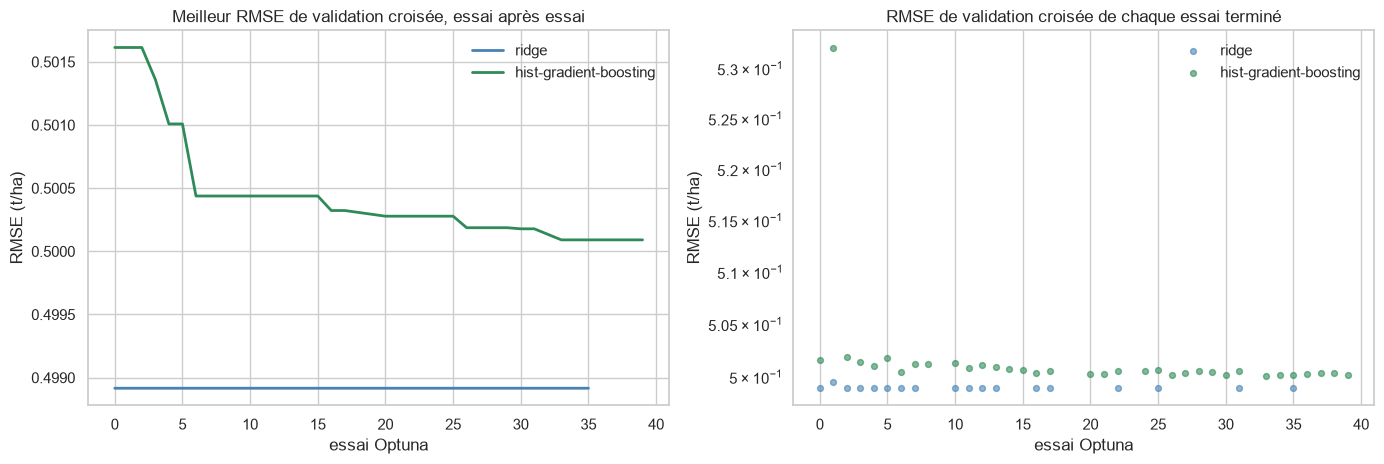

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
colors = {"ridge": "steelblue", "hist-gradient-boosting": "seagreen"}

for name, s in studies.items():
    done = s.trials_dataframe()
    done = done[done["state"] == "COMPLETE"]
    axes[0].plot(done["number"], done["value"].cummin(), color=colors[name], lw=2, label=name)
    axes[1].scatter(done["number"], done["value"], s=18, alpha=.6, color=colors[name], label=name)

axes[0].set_title("Meilleur RMSE de validation croisée, essai après essai")
axes[1].set_title("RMSE de validation croisée de chaque essai terminé")
for ax in axes:
    ax.set_xlabel("essai Optuna"); ax.set_ylabel("RMSE (t/ha)"); ax.legend(frameon=False)
axes[1].set_yscale("log")
plt.tight_layout(); plt.savefig(FIG_DIR / "30_optuna_historique.png", dpi=120); plt.show()

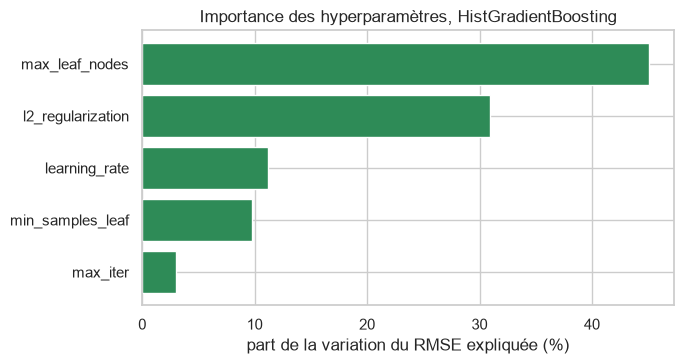

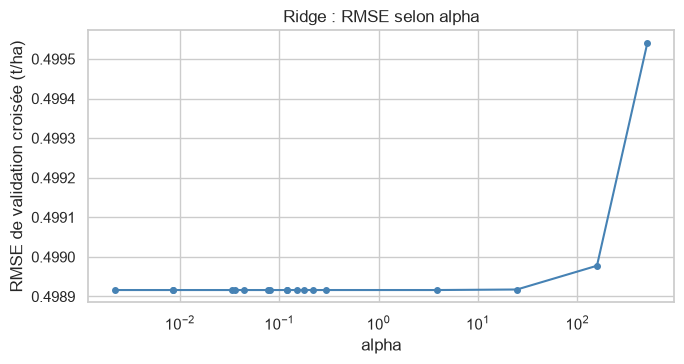

In [9]:
hgb = studies["hist-gradient-boosting"]
importances = optuna.importance.get_param_importances(hgb)

plt.figure(figsize=(7, 3.8))
names = list(importances)[::-1]
plt.barh(names, [importances[n] * 100 for n in names], color="seagreen")
plt.xlabel("part de la variation du RMSE expliquée (%)")
plt.title("Importance des hyperparamètres, HistGradientBoosting")
plt.tight_layout(); plt.savefig(FIG_DIR / "31_optuna_importance_hgb.png", dpi=120); plt.show()

ridge_df = studies["ridge"].trials_dataframe()
ridge_df = ridge_df[ridge_df["state"] == "COMPLETE"].sort_values("params_alpha")
plt.figure(figsize=(7, 3.8))
plt.plot(ridge_df["params_alpha"], ridge_df["value"], "o-", color="steelblue", ms=4)
plt.xscale("log"); plt.xlabel("alpha"); plt.ylabel("RMSE de validation croisée (t/ha)")
plt.title("Ridge : RMSE selon alpha")
plt.tight_layout(); plt.savefig(FIG_DIR / "32_optuna_ridge_alpha.png", dpi=120); plt.show()

## 8. Réentraînement sur le jeu d'entraînement complet et évaluation

Pour chaque modèle, deux versions sont entraînées sur l'ensemble du jeu d'entraînement : hyperparamètres par défaut (référence) et hyperparamètres Optuna. Chaque version fait l'objet d'un run MLflow avec métriques train et test, écarts train / test, temps d'entraînement et pipeline complet.

In [10]:
def fit_and_log(run_name, name, params, stage, extra_metrics=None):
    pipe = build_pipeline(name, params)
    with mlflow.start_run(run_name=run_name) as run:
        mlflow.set_tags({"stage": stage, "model_name": name, "target": TARGET})
        mlflow.log_params({"seed": SEED, "n_train": len(X_train_full), "n_test": len(X_test),
                           "features": ",".join(FEATURES), **{f"param_{k}": v for k, v in params.items()}})
        t0 = time.perf_counter()
        pipe.fit(X_train_full, y_train_full)
        fit_time = time.perf_counter() - t0
        m_train = evaluate(pipe, X_train_full, y_train_full)
        m_test = evaluate(pipe, X_test, y_test)
        mlflow.log_metrics({
            "train_rmse": m_train["rmse"], "train_mae": m_train["mae"], "train_r2": m_train["r2"],
            "test_rmse": m_test["rmse"], "test_mae": m_test["mae"], "test_r2": m_test["r2"],
            "gap_r2_train_minus_test": m_train["r2"] - m_test["r2"],
            "fit_time_s": fit_time, **(extra_metrics or {}),
        })
        log_pipeline(pipe, X_train_full.head(1000))
    return pipe, {
        "run_name": run_name, "run_id": run.info.run_id, "model": name, "stage": stage,
        "test_rmse": m_test["rmse"], "test_mae": m_test["mae"], "test_r2": m_test["r2"],
        "train_rmse": m_train["rmse"], "gap_r2": m_train["r2"] - m_test["r2"], "fit_time_s": fit_time,
    }


pipes, rows = {}, []
for name in MODEL_NAMES:
    pipe_ref, row_ref = fit_and_log(f"reference-{name}-defaut", name, {}, "reference-full")
    pipe_opt, row_opt = fit_and_log(f"final-{name}-optuna", name, studies[name].best_params, "final-optuna",
                                    extra_metrics={"cv_rmse_optuna": studies[name].best_value})
    pipes[f"reference-{name}-defaut"], pipes[f"final-{name}-optuna"] = pipe_ref, pipe_opt
    rows += [row_ref, row_opt]
    print(f"{name:24s} défaut : test RMSE {row_ref['test_rmse']:.4f} | Optuna : test RMSE {row_opt['test_rmse']:.4f}")

final_results = pd.DataFrame(rows).sort_values("test_rmse").reset_index(drop=True)

c:\Users\ethan\Documents\OpenClassrooms\agritech-answers\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/06 12:02:41 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, w

c:\Users\ethan\Documents\OpenClassrooms\agritech-answers\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/06 12:02:49 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, w

ridge                    défaut : test RMSE 0.4993 | Optuna : test RMSE 0.4993


c:\Users\ethan\Documents\OpenClassrooms\agritech-answers\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/06 12:03:00 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, w

c:\Users\ethan\Documents\OpenClassrooms\agritech-answers\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/06 12:03:20 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, w

hist-gradient-boosting   défaut : test RMSE 0.4997 | Optuna : test RMSE 0.4995


In [11]:
final_results[["run_name", "test_rmse", "test_mae", "test_r2", "train_rmse", "gap_r2", "fit_time_s"]].round(4)

,run_name,test_rmse,test_mae,test_r2,train_rmse,gap_r2,fit_time_s
0,reference-ridge-defaut,0.4993,0.3983,0.9132,0.5003,-0.0003,1.5088
1,final-ridge-optuna,0.4993,0.3983,0.9132,0.5003,-0.0003,1.3946
2,final-hist-gradient-boosting-optuna,0.4995,0.3985,0.9132,0.5002,-0.0002,10.4906
3,reference-hist-gradient-boosting-defaut,0.4997,0.3987,0.9131,0.4996,0.0000,4.1916


### Test apparié sur les erreurs du jeu de test

Comparaison des erreurs quadratiques observation par observation entre les deux modèles optimisés. Une statistique z supérieure à 2 en valeur absolue indique un écart systématique ; elle ne renseigne pas sur son importance pratique.

In [12]:
def paired_z(pipe_a, pipe_b):
    err_a = (y_test.to_numpy() - pipe_a.predict(X_test)) ** 2
    err_b = (y_test.to_numpy() - pipe_b.predict(X_test)) ** 2
    d = err_b - err_a
    return float(d.mean() / (d.std(ddof=1) / np.sqrt(len(d))))


pipe_ridge = pipes["final-ridge-optuna"]
pipe_hgb = pipes["final-hist-gradient-boosting-optuna"]
z = paired_z(pipe_ridge, pipe_hgb)
rmse_ridge = final_results.set_index("run_name").loc["final-ridge-optuna", "test_rmse"]
rmse_hgb = final_results.set_index("run_name").loc["final-hist-gradient-boosting-optuna", "test_rmse"]
print(f"RMSE test : ridge {rmse_ridge:.4f} | hist-gradient-boosting {rmse_hgb:.4f} | écart {rmse_hgb - rmse_ridge:+.4f} t/ha")
print(f"z (erreur quadratique hist-gradient-boosting moins ridge) = {z:.2f} -> {'écart systématique' if abs(z) > 2 else 'écart indiscernable'}")

RMSE test : ridge 0.4993 | hist-gradient-boosting 0.4995 | écart +0.0002 t/ha
z (erreur quadratique hist-gradient-boosting moins ridge) = 5.55 -> écart systématique


## 9. Sélection du modèle final

Règle appliquée sur le RMSE de validation croisée (le jeu de test n'intervient pas) : le modèle linéaire est retenu si son RMSE est inférieur au meilleur RMSE augmenté d'une tolérance `TOLERANCE_SELECTION`, sinon le modèle au plus faible RMSE est retenu.

In [13]:
best_cv = {name: studies[name].best_value for name in MODEL_NAMES}
lowest = min(best_cv.values())
if best_cv[SIMPLE_MODEL] <= lowest + TOLERANCE_SELECTION:
    selected = SIMPLE_MODEL
else:
    selected = min(best_cv, key=best_cv.get)

print("RMSE de validation croisée :", {k: round(v, 4) for k, v in best_cv.items()})
print(f"Tolérance : {TOLERANCE_SELECTION} | modèle retenu : {selected}")

selected_run = f"final-{selected}-optuna"
selected_pipe = pipes[selected_run]
sel = final_results.set_index("run_name").loc[selected_run]
print(f"Test : RMSE {sel['test_rmse']:.4f} t/ha | MAE {sel['test_mae']:.4f} t/ha | R2 {sel['test_r2']:.4f}")

RMSE de validation croisée : {'ridge': 0.4989, 'hist-gradient-boosting': 0.5001}
Tolérance : 0.001 | modèle retenu : ridge
Test : RMSE 0.4993 t/ha | MAE 0.3983 t/ha | R2 0.9132


## 10. Contrôle des prédictions du modèle retenu

Réel contre prédit et résidus sur le jeu de test.

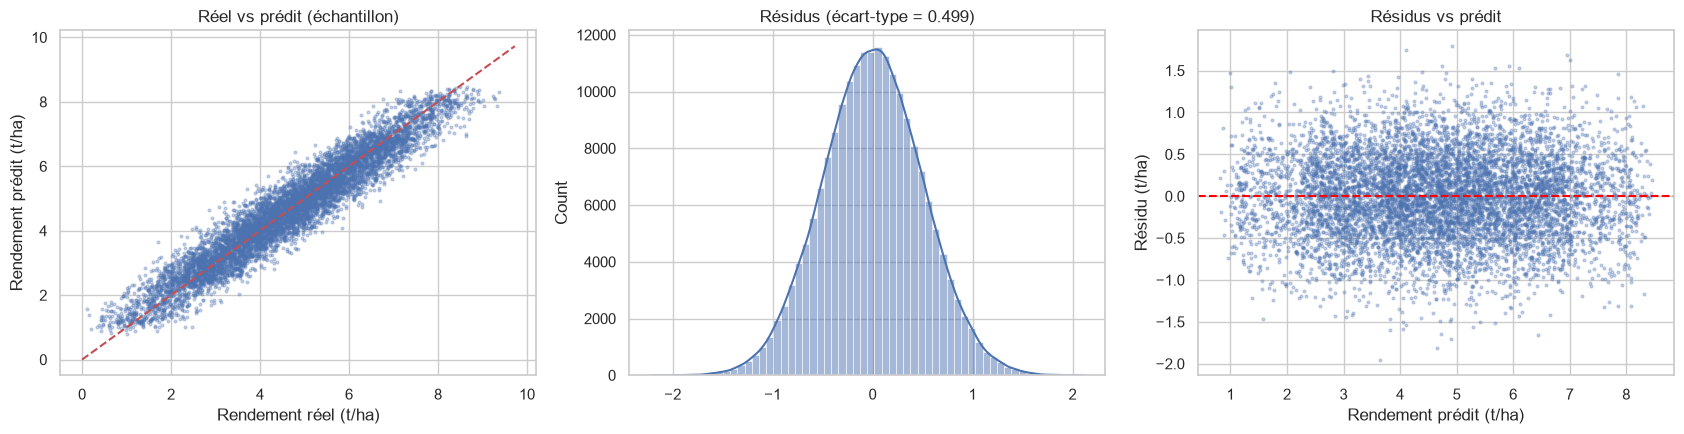

Biais moyen des résidus : +0.0001 t/ha


In [14]:
pred = selected_pipe.predict(X_test)
resid = y_test.to_numpy() - pred
idx = np.random.default_rng(SEED).choice(len(y_test), min(8000, len(y_test)), replace=False)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].scatter(y_test.to_numpy()[idx], pred[idx], s=4, alpha=.3)
lim = [0, max(y_test.max(), pred.max())]
ax[0].plot(lim, lim, "r--"); ax[0].set_xlabel("Rendement réel (t/ha)"); ax[0].set_ylabel("Rendement prédit (t/ha)")
ax[0].set_title("Réel vs prédit (échantillon)")
sns.histplot(resid, bins=60, kde=True, ax=ax[1]); ax[1].set_title(f"Résidus (écart-type = {resid.std():.3f})")
ax[2].scatter(pred[idx], resid[idx], s=4, alpha=.3); ax[2].axhline(0, color="red", ls="--")
ax[2].set_xlabel("Rendement prédit (t/ha)"); ax[2].set_ylabel("Résidu (t/ha)"); ax[2].set_title("Résidus vs prédit")
plt.tight_layout(); plt.savefig(FIG_DIR / "33_diagnostic_modele_final.png", dpi=120); plt.show()
print(f"Biais moyen des résidus : {resid.mean():+.4f} t/ha")

## 11. Effet de la culture sur les prédictions

Pour 2 000 contextes du jeu de test, le rendement est prédit avec le modèle retenu pour chacune des cultures, le contexte restant identique.

In [15]:
ctx = X_test.sample(2000, random_state=SEED).reset_index(drop=True)
pred_by_crop = pd.DataFrame({c: selected_pipe.predict(ctx.assign(Crop=c)) for c in crops})
spread = pred_by_crop.max(axis=1) - pred_by_crop.min(axis=1)

print("Écart (max - min) entre cultures pour un même contexte (t/ha) :")
print(spread.describe().round(4))
print("\nRendement prédit moyen par culture (t/ha) :")
print(pred_by_crop.mean().round(4))
print(f"\nRMSE du modèle sur le test : {sel['test_rmse']:.3f} t/ha")
print("\nCulture classée première (part des contextes) :")
print(pred_by_crop.idxmax(axis=1).value_counts(normalize=True).round(3))

Écart (max - min) entre cultures pour un même contexte (t/ha) :
count    2000.0000
mean        0.0028
std         0.0000
min         0.0028
25%         0.0028
50%         0.0028
75%         0.0028
max         0.0028
dtype: float64

Rendement prédit moyen par culture (t/ha) :
Barley     4.7040
Cotton     4.7030
Maize      4.7012
Rice       4.7039
Soybean    4.7022
Wheat      4.7015
dtype: float64

RMSE du modèle sur le test : 0.499 t/ha

Culture classée première (part des contextes) :
Barley    1.0
Name: proportion, dtype: float64


## 12. Export et enregistrement du modèle retenu

Export du pipeline complet au format `joblib` dans `models/`, relecture de contrôle, puis enregistrement dans le Model Registry MLflow avec l'alias `champion`.

In [16]:
model_path = MODELS_DIR / "final_model.joblib"
joblib.dump(selected_pipe, model_path)

reloaded = joblib.load(model_path)
same = np.allclose(reloaded.predict(X_test.head(200)), selected_pipe.predict(X_test.head(200)))
print(f"Exporté : {model_path} ({model_path.stat().st_size / 1024:.1f} Ko) | prédictions identiques après relecture : {same}")

meta = {
    "model": selected, "features": FEATURES, "target": TARGET, "seed": SEED,
    "best_params": studies[selected].best_params,
    "cv_rmse": best_cv[selected],
    "test_rmse": float(sel["test_rmse"]), "test_mae": float(sel["test_mae"]), "test_r2": float(sel["test_r2"]),
    "categories": {c: sorted(X_train_full[c].unique().tolist()) for c in cat_cols},
}
(MODELS_DIR / "final_model_metadata.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")
print("Métadonnées exportées :", MODELS_DIR / "final_model_metadata.json")

Exporté : ..\models\final_model.joblib (4.5 Ko) | prédictions identiques après relecture : True
Métadonnées exportées : ..\models\final_model_metadata.json


In [17]:
client = MlflowClient()
run_id = final_results.set_index("run_name").loc[selected_run, "run_id"]
try:
    version = mlflow.register_model(f"runs:/{run_id}/model", REGISTRY_NAME)
    client.set_registered_model_alias(REGISTRY_NAME, "champion", version.version)
    client.set_model_version_tag(REGISTRY_NAME, version.version, "selected_model", selected)
    print(f"Modèle enregistré : {REGISTRY_NAME} version {version.version} | alias champion | URI : models:/{REGISTRY_NAME}@champion")
except Exception as e:
    print("Enregistrement dans le registre impossible :", e)

Successfully registered model 'crop-yield-regressor'.
2026/11/06 12:03:29 WARNING mlflow.tracking._model_registry.fluent: Run with id ce52fbe1a31640ac83591a143aa72d1f has no artifacts at artifact path 'model', registering model based on models:/m-f3eac036fc4e4fb4a0f904bd5455f84e instead


Modèle enregistré : crop-yield-regressor version 1 | alias champion | URI : models:/crop-yield-regressor@champion


Created version '1' of model 'crop-yield-regressor'.


## 13. Synthèse

In [18]:
ref_rmse = final_results.set_index("run_name").loc[f"reference-{selected}-defaut", "test_rmse"]
print(f"Modèle retenu : {selected} | hyperparamètres : {studies[selected].best_params}")
print(f"RMSE de validation croisée : {best_cv[selected]:.4f} t/ha")
print(f"RMSE test : {sel['test_rmse']:.4f} t/ha | MAE test : {sel['test_mae']:.4f} t/ha | R2 test : {sel['test_r2']:.4f}")
print(f"RMSE test avec hyperparamètres par défaut : {ref_rmse:.4f} t/ha | variation due à l'optimisation : {sel['test_rmse'] - ref_rmse:+.4f} t/ha")
print(f"Écart entre cultures prédit : {spread.mean():.4f} t/ha en moyenne, pour un RMSE de {sel['test_rmse']:.3f} t/ha")
print(f"Runs de l'expérience {EXPERIMENT_NAME} : {len(mlflow.search_runs(experiment_names=[EXPERIMENT_NAME]))} | interface : {MLFLOW_URL}")

Modèle retenu : ridge | hyperparamètres : {'alpha': 0.29777512170763604}
RMSE de validation croisée : 0.4989 t/ha
RMSE test : 0.4993 t/ha | MAE test : 0.3983 t/ha | R2 test : 0.9132
RMSE test avec hyperparamètres par défaut : 0.4993 t/ha | variation due à l'optimisation : +0.0000 t/ha
Écart entre cultures prédit : 0.0028 t/ha en moyenne, pour un RMSE de 0.499 t/ha
Runs de l'expérience crop-yield-optimisation : 86 | interface : http://127.0.0.1:5000
